[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DEDJIABDOUL/omicaa-lab-machine-learning-bioinformatics/blob/main/notebooks/03_visualisation_et_pretraitement.ipynb)

# Notebook 03 : visualisation, valeurs atypiques et prétraitement sans fuite d'information

**Omicaa Lab | Machine Learning et Deep Learning pour les biologistes** | Auteur : DEDJI ABDOUL BATINOU

## Introduction scientifique

Visualiser avant de modéliser est une exigence méthodologique : un graphique révèle en quelques secondes une unité erronée, un déséquilibre ou une redondance que des statistiques résumées masquent. Ce notebook explore le jeu Breast Cancer Wisconsin avec Matplotlib, établit une grille de lecture des valeurs atypiques, puis introduit les transformations de scikit-learn en insistant sur la règle qui conditionne la validité de tout le reste du parcours : un prétraitement s'ajuste sur l'entraînement seul.

## Objectifs techniques

1. Produire des figures Matplotlib interprétables : histogrammes, boîtes, nuage de points, matrice de corrélation.
2. Distinguer anomalie technique, valeur atypique et observation biologiquement plausible.
3. Utiliser SimpleImputer, StandardScaler, OneHotEncoder et ColumnTransformer.
4. Partitionner les données avec stratification et démontrer concrètement la fuite d'information.

## Prérequis

* Notebook 02 terminé : DataFrame, filtrage, cible recodée.

## Résultat attendu

Un partitionnement stratifié validé, des figures sauvegardées dans `figures/` et une démonstration chiffrée de l'écart entre un ajustement correct et un ajustement fautif d'un normalisateur.

## 1. Contrôle de l'environnement et chargement des données

In [1]:
import sys, platform, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
from sklearn.datasets import load_breast_cancer
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.12.3
NumPy       : 2.4.4
pandas      : 3.0.2
Matplotlib  : 3.10.8
scikit-learn: 1.8.0


In [2]:
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# Charte graphique Omicaa Lab : rouge pour l'attention (classe maligne), cyan pour l'information secondaire, noir pour la structure.
ROUGE, CYAN, NOIR, GRIS = "#FF0000", "#0097B2", "#000000", "#8A8A8A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": NOIR, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.labelsize": 9.5, "font.size": 9.5})

bunch = load_breast_cancer(as_frame=True)
X = bunch.data.copy()
y = (bunch.target == 0).astype(int).rename("maligne")      # 1 = maligne (classe positive), 0 = bénigne
nom_classe = y.map({0: "bénigne", 1: "maligne"})

# Étape B : validation des entrées
assert X.shape == (569, 30) and X.isna().sum().sum() == 0
assert X.index.equals(y.index) and set(y.unique()) == {0, 1}
print("Données validées :", X.shape, "| malignes :", int(y.sum()), "| bénignes :", int((1 - y).sum()))

Données validées : (569, 30) | malignes : 212 | bénignes : 357


## 2. Matplotlib : figure, axes, artistes

On travaille avec l'interface orientée objet : `fig, ax = plt.subplots()` crée une figure et ses axes, puis on appelle les méthodes de `ax`. Cette écriture est plus explicite que `plt.plot` et s'étend naturellement aux figures à plusieurs panneaux.

**Distribution de la cible.** Un diagramme en barres vérifie visuellement l'équilibre des classes.

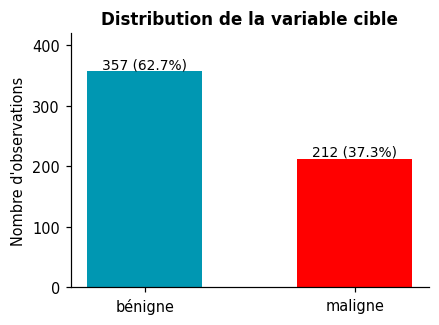

In [3]:
fig, ax = plt.subplots(figsize=(4.2, 3.0))
effectifs = nom_classe.value_counts().reindex(["bénigne", "maligne"])
barres = ax.bar(effectifs.index, effectifs.values, color=[CYAN, ROUGE], width=0.55)
for b, v in zip(barres, effectifs.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 5, f"{v} ({v / len(y):.1%})", ha="center", fontsize=9)
ax.set_ylabel("Nombre d'observations")
ax.set_title("Distribution de la variable cible")
ax.set_ylim(0, 420)
fig.savefig(FIG / "fig_cible.png", dpi=170, bbox_inches="tight")
plt.show()

**Distribution des variables selon la classe.** Un histogramme superposé révèle si une caractéristique sépare les groupes. L'option `density=True` normalise l'aire de chaque histogramme et permet de comparer des classes d'effectifs différents.

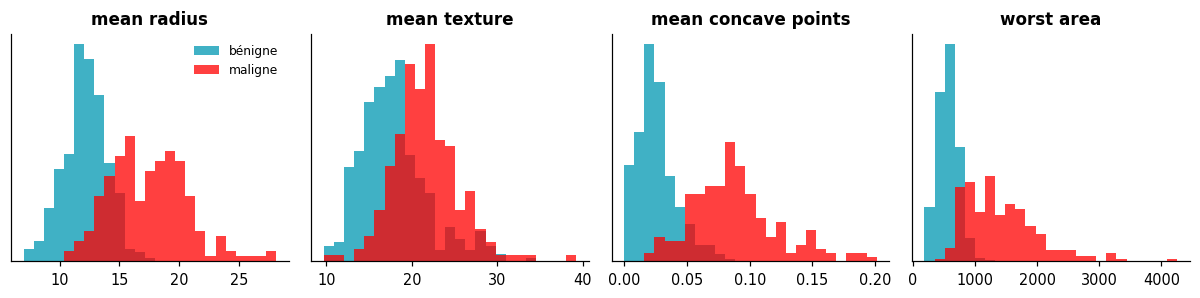

In [4]:
choix = ["mean radius", "mean texture", "mean concave points", "worst area"]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, col in zip(axes, choix):
    bornes = np.linspace(X[col].min(), X[col].max(), 26)
    ax.hist(X.loc[y == 0, col], bins=bornes, alpha=0.75, color=CYAN, density=True, label="bénigne")
    ax.hist(X.loc[y == 1, col], bins=bornes, alpha=0.75, color=ROUGE, density=True, label="maligne")
    ax.set_title(col)
    ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig_histogrammes.png", dpi=170, bbox_inches="tight")
plt.show()

**Lecture.** `mean radius`, `mean concave points` et `worst area` montrent un décalage net entre les classes ; `mean texture` chevauche davantage. Une caractéristique dont les distributions se recouvrent reste utile en combinaison avec d'autres, mais elle sépare mal les classes à elle seule.

**Relation entre deux variables.** Le nuage de points ajoute la dimension de la relation conjointe.

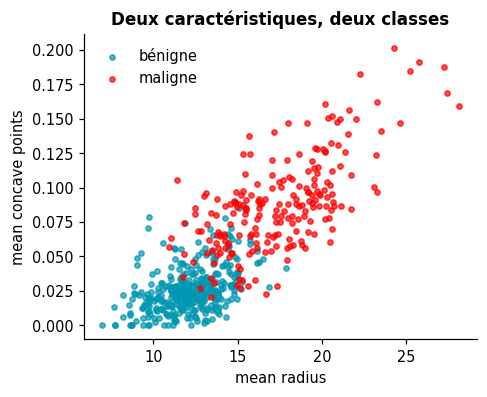

In [5]:
fig, ax = plt.subplots(figsize=(4.6, 3.6))
for classe, couleur, nom in [(0, CYAN, "bénigne"), (1, ROUGE, "maligne")]:
    m = y == classe
    ax.scatter(X.loc[m, "mean radius"], X.loc[m, "mean concave points"], s=12, alpha=0.7, color=couleur, label=nom)
ax.set_xlabel("mean radius")
ax.set_ylabel("mean concave points")
ax.set_title("Deux caractéristiques, deux classes")
ax.legend(frameon=False)
fig.savefig(FIG / "fig_nuage.png", dpi=170, bbox_inches="tight")
plt.show()

## 3. Corrélations : des mesures redondantes

Le coefficient de corrélation de Pearson mesure la **dépendance linéaire** entre deux variables, de -1 à 1. Une forte corrélation entre caractéristiques signifie que la matrice `X` contient de l'information redondante. Rayon, périmètre et aire décrivent la même grandeur géométrique : ils ne sont pas indépendants.

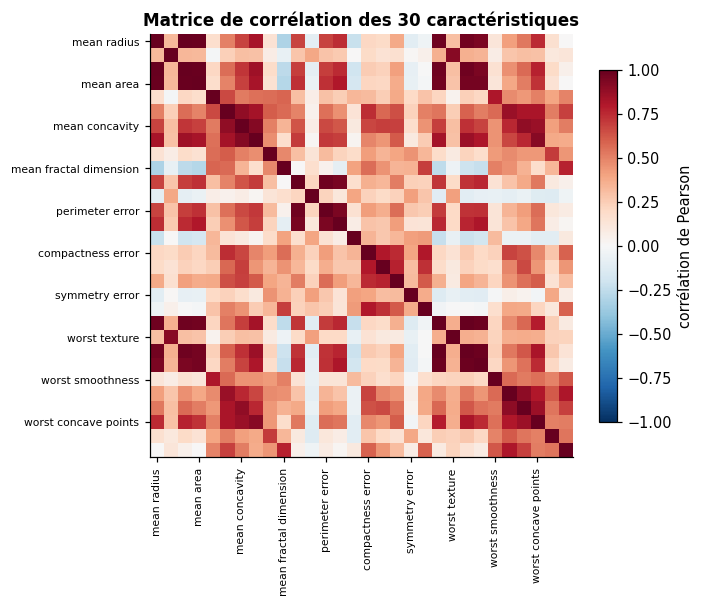

paires de caractéristiques avec |r| > 0.9 : 21 sur 900
mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984
dtype: float64


In [6]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(0, 30, 3)); ax.set_xticklabels(corr.columns[::3], rotation=90, fontsize=7)
ax.set_yticks(range(0, 30, 3)); ax.set_yticklabels(corr.columns[::3], fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="corrélation de Pearson")
ax.set_title("Matrice de corrélation des 30 caractéristiques")
fig.savefig(FIG / "fig_correlation.png", dpi=170, bbox_inches="tight")
plt.show()

haut = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
paires = haut.stack()
fortes = paires[paires.abs() > 0.9].sort_values(ascending=False)
print("paires de caractéristiques avec |r| > 0.9 :", len(fortes), "sur", len(paires))
print(fortes.head(5).round(3))

**Conséquence.** Des caractéristiques très corrélées rendent instables les coefficients d'une régression logistique (on ne peut pas attribuer l'effet à l'une plutôt qu'à l'autre) et réduisent la portée d'une lecture directe des importances. Elles ne dégradent pas nécessairement la performance prédictive.

## 4. Valeurs atypiques : trois situations à ne pas confondre

| Situation | Définition | Décision |
|---|---|---|
| Anomalie technique | valeur impossible ou incohérente (unité erronée, erreur de saisie, artefact de mesure) | corriger, exclure ou signaler, avec traçabilité |
| Valeur atypique | valeur éloignée de la masse des observations, sans impossibilité démontrée | examiner, conserver par défaut, évaluer l'effet sur le modèle |
| Observation biologiquement plausible | valeur extrême mais compatible avec le phénomène | conserver : elle porte une information |

Une règle statistique (écart interquartile, score z) **repère** des candidats. Elle ne tranche jamais seule : la décision exige une connaissance du phénomène et de la mesure.

In [7]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
hors = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)

print("observations avec au moins une valeur hors bornes IQR :", int(hors.any(axis=1).sum()), "sur", len(X))
print("colonnes les plus concernées :")
print(hors.sum().sort_values(ascending=False).head(5))

part_maligne_atypiques = y[hors.any(axis=1)].mean()
print(f"part de tumeurs malignes parmi les observations atypiques : {part_maligne_atypiques:.3f} (globalement : {y.mean():.3f})")

observations avec au moins une valeur hors bornes IQR : 171 sur 569
colonnes les plus concernées :
area error          65
radius error        38
perimeter error     38
worst area          35
smoothness error    30
dtype: int64
part de tumeurs malignes parmi les observations atypiques : 0.667 (globalement : 0.373)


Les observations atypiques sont surreprésentées parmi les tumeurs malignes. Ce sont donc des mesures **porteuses du signal** que l'on cherche à prédire : les supprimer reviendrait à retirer une partie de l'information utile. On vérifie maintenant l'absence d'anomalie technique par des tests de cohérence physique.

In [8]:
# Un noyau quasi circulaire vérifie : périmètre voisin de 2 pi r et aire voisine de pi r au carré.
ratio_perimetre = X["mean perimeter"] / (2 * np.pi * X["mean radius"])
ratio_aire = X["mean area"] / (np.pi * X["mean radius"] ** 2)
print("périmètre / (2 pi r) : min", ratio_perimetre.min().round(3), "| max", ratio_perimetre.max().round(3))
print("aire / (pi r^2)      : min", ratio_aire.min().round(3), "| max", ratio_aire.max().round(3))

assert (X[[c for c in X.columns if "radius" in c or "area" in c or "perimeter" in c]] > 0).all().all()
assert ratio_perimetre.between(0.8, 1.4).all() and ratio_aire.between(0.8, 1.4).all()
idx_max = X["mean area"].idxmax()
print("observation d'aire maximale :", idx_max, "| aire =", X.loc[idx_max, "mean area"], "| maligne =", int(y.loc[idx_max]))

périmètre / (2 pi r) : min 0.983 | max 1.133
aire / (pi r^2)      : min 0.917 | max 1.064
observation d'aire maximale : 461 | aire = 2501.0 | maligne = 1


Aucune incohérence géométrique n'est détectée : les grandeurs mesurées sont mutuellement compatibles. L'observation d'aire maximale est la plus grande de l'échantillon et elle est classée maligne : c'est une **observation plausible**, à conserver. Ce contrôle ne prouve pas l'absence de toute erreur (une erreur cohérente passerait inaperçue) mais il élimine les erreurs d'unité grossières.

## 5. Prétraitement : des transformations qui apprennent

Certaines transformations calculent des **paramètres à partir des données** : la moyenne et l'écart type pour `StandardScaler`, la médiane pour `SimpleImputer`, la liste des catégories pour `OneHotEncoder`. L'API scikit-learn distingue deux étapes :

* `fit(X_train)` : estimer les paramètres, sur l'entraînement uniquement ;
* `transform(X)` : appliquer ces paramètres, à l'entraînement comme à la validation et au test.

Estimer ces paramètres avec les données de test introduit une **fuite d'information** : le test n'est plus indépendant du modèle. L'effet est parfois faible, parfois considérable, mais la faute de méthode est la même.

### 5.1 Table fictive pour apprendre l'imputation et l'encodage

Le jeu Wisconsin ne contient ni valeur manquante ni variable catégorielle. Pour apprendre ces outils, on construit une petite table **entièrement fictive** (aucune donnée réelle) qui présente une variable numérique avec trous, une variable numérique complète et une variable catégorielle.

In [9]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

fictif = pd.DataFrame({
    "age":        [34, 51, np.nan, 47, 62, 29, np.nan, 55],
    "expression": [5.1, 8.3, 6.0, 7.7, 9.4, 4.8, 6.6, 8.9],
    "centre":     ["A", "B", "A", np.nan, "C", "B", "A", "C"],
})
print(fictif)
print("\nvaleurs manquantes par colonne :\n", fictif.isna().sum().to_dict())

numeriques, categorielles = ["age", "expression"], ["centre"]
pretraitement = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeriques),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorielles),
])
train_f, test_f = fictif.iloc[:6], fictif.iloc[6:]
matrice_train = pretraitement.fit_transform(train_f)
matrice_test = pretraitement.transform(test_f)
noms = pretraitement.get_feature_names_out()
print("\ncolonnes produites :", list(noms))
print(pd.DataFrame(matrice_train, columns=noms).round(2))
assert matrice_train.shape == (6, 5) and matrice_test.shape == (2, 5)
assert not np.isnan(matrice_train).any() and not np.isnan(matrice_test).any()

    age  expression centre
0  34.0         5.1      A
1  51.0         8.3      B
2   NaN         6.0      A
3  47.0         7.7    NaN
4  62.0         9.4      C
5  29.0         4.8      B
6   NaN         6.6      A
7  55.0         8.9      C

valeurs manquantes par colonne :
 {'age': 2, 'expression': 0, 'centre': 1}

colonnes produites : ['num__age', 'num__expression', 'cat__centre_A', 'cat__centre_B', 'cat__centre_C']
   num__age  num__expression  cat__centre_A  cat__centre_B  cat__centre_C
0     -1.01            -1.05            1.0            0.0            0.0
1      0.55             0.83            0.0            1.0            0.0
2      0.18            -0.52            1.0            0.0            0.0
3      0.18             0.48            1.0            0.0            0.0
4      1.56             1.48            0.0            0.0            1.0
5     -1.47            -1.23            0.0            1.0            0.0


**Points à retenir.** La médiane de `age` est calculée sur les 6 lignes d'entraînement puis réutilisée pour remplir le trou de la ligne de test. Le `OneHotEncoder` transforme `centre` en trois colonnes binaires. Avec `handle_unknown="ignore"`, une catégorie absente de l'entraînement produit une ligne de zéros au lieu d'une erreur. Le `ColumnTransformer` applique à chaque groupe de colonnes sa propre chaîne de transformations et reconstitue une matrice unique.

In [10]:
nouveau = pd.DataFrame({"age": [40.0], "expression": [7.0], "centre": ["D"]})   # centre D jamais vu à l'entraînement
print(pretraitement.transform(nouveau).round(2))

[[-0.46  0.07  0.    0.    0.  ]]


**LabelEncoder.** Il convertit des étiquettes textuelles en entiers. Il est conçu pour la **cible** et non pour les caractéristiques : il attribue des entiers par ordre alphabétique, ce qui suggère une hiérarchie inexistante entre catégories. Pour des variables explicatives catégorielles, on utilise `OneHotEncoder`.

In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder().fit(nom_classe)
print("classes triées :", list(le.classes_), "->", le.transform(list(le.classes_)).tolist())
assert (le.transform(nom_classe) == y.values).all()   # même codage que notre recodage manuel

classes triées : ['bénigne', 'maligne'] -> [0, 1]


## 6. Partitionnement stratifié

`train_test_split` découpe les données en un jeu d'entraînement et un jeu de test. Trois arguments comptent :

* `test_size` : la fraction réservée au test (ici 20 %) ;
* `random_state` : la graine, qui rend le tirage reproductible ;
* `stratify=y` : la répartition des classes est conservée dans chaque partie, ce qui est important lorsque les classes sont déséquilibrées ou que l'effectif est modeste.

**Règle de conduite.** Le jeu de test est réservé à l'évaluation finale. Il ne sert ni à choisir un modèle, ni à régler un hyperparamètre, ni à décider d'une transformation.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print("entraînement :", X_train.shape, "| test :", X_test.shape)
print("part maligne : globale", round(y.mean(), 3), "| train", round(y_train.mean(), 3), "| test", round(y_test.mean(), 3))
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(X_test.index)
assert abs(y_train.mean() - y_test.mean()) < 0.01       # stratification effective
assert "maligne" not in X_train.columns

entraînement : (455, 30) | test : (114, 30)
part maligne : globale 0.373 | train 0.374 | test 0.368


## 7. Démonstration de la fuite d'information

On compare deux manières d'ajuster un `StandardScaler` : correcte (sur l'entraînement) et fautive (sur toutes les données, test compris).

In [13]:
scaler_correct = StandardScaler().fit(X_train)
scaler_fautif = StandardScaler().fit(X)          # le test participe à l'estimation : fuite

col = "mean area"
j = list(X.columns).index(col)
print(f"{col} : moyenne apprise sur train = {scaler_correct.mean_[j]:.2f} | sur toutes les données = {scaler_fautif.mean_[j]:.2f}")
ecart_max = np.abs(scaler_correct.mean_ - scaler_fautif.mean_) / X.std().values
print("écart maximal entre les deux moyennes, en écarts types :", ecart_max.max().round(3))

Z_test = scaler_correct.transform(X_test)
print("moyenne du test après mise à l'échelle correcte (max sur colonnes) :", np.abs(Z_test.mean(axis=0)).max().round(3))

mean area : moyenne apprise sur train = 659.58 | sur toutes les données = 654.89
écart maximal entre les deux moyennes, en écarts types : 0.049
moyenne du test après mise à l'échelle correcte (max sur colonnes) : 0.255


Les deux moyennes diffèrent légèrement : l'effet numérique est ici modeste, car l'échantillon est de taille raisonnable et le test n'est qu'un cinquième des données. Il serait bien plus marqué sur un petit échantillon ou avec une sélection supervisée de variables (notebook 07). Le test, correctement transformé, n'est **pas** exactement centré en zéro : c'est normal et attendu, puisqu'il est mis à l'échelle avec des paramètres qu'il n'a pas influencés.

La solution structurelle est de ne jamais appeler `fit` à la main sur des transformateurs : on les enferme dans un `Pipeline` (notebook 04), qui garantit l'ordre correct à chaque appel de `fit`, y compris à l'intérieur d'une validation croisée.

## 8. Exercices progressifs

**Exercice 1.** Tracez la boîte à moustaches de `mean texture` pour chaque classe (`ax.boxplot`) et dites si l'une des deux classes a une dispersion nettement plus grande.

*Solution de l'exercice 1*

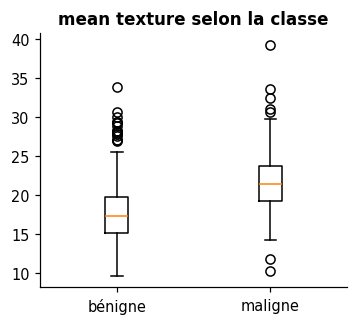

         median   std
maligne              
bénigne   17.39  4.00
maligne   21.46  3.78


In [14]:
fig, ax = plt.subplots(figsize=(3.6, 3))
ax.boxplot([X.loc[y == 0, "mean texture"], X.loc[y == 1, "mean texture"]], tick_labels=["bénigne", "maligne"])
ax.set_title("mean texture selon la classe")
plt.show()
print(X.groupby(nom_classe)["mean texture"].agg(["median", "std"]).round(2))

**Exercice 2.** Appliquez la règle de l'écart interquartile à `mean radius` seule. Combien d'observations sont hors bornes, et combien sont malignes ?

*Solution de l'exercice 2*

In [15]:
col = "mean radius"
bas, haut_ = q1[col] - 1.5 * iqr[col], q3[col] + 1.5 * iqr[col]
sel = (X[col] < bas) | (X[col] > haut_)
print("hors bornes :", int(sel.sum()), "| malignes :", int(y[sel].sum()))
assert int(sel.sum()) == int(hors[col].sum())

hors bornes : 14 | malignes : 14


**Exercice 3.** Réalisez un second partitionnement avec `random_state=7`. Les effectifs changent-ils ? Les proportions de classes restent-elles stables ?

*Solution de l'exercice 3*

In [16]:
_, Xt2, _, yt2 = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)
print(len(Xt2), round(yt2.mean(), 3))
assert len(Xt2) == len(X_test) and abs(yt2.mean() - y_test.mean()) < 0.01
print("Les effectifs et proportions sont identiques, mais les observations choisies diffèrent :",
      len(set(Xt2.index) & set(X_test.index)), "observations en commun sur", len(Xt2))

114 0.368
Les effectifs et proportions sont identiques, mais les observations choisies diffèrent : 24 observations en commun sur 114


**Exercice 4.** Dans la table fictive, remplacez la stratégie d'imputation `median` par `mean`. Les valeurs imputées changent-elles ?

*Solution de l'exercice 4*

In [17]:
imp_med = SimpleImputer(strategy="median").fit(train_f[["age"]])
imp_moy = SimpleImputer(strategy="mean").fit(train_f[["age"]])
print("valeur imputée (médiane) :", imp_med.statistics_, "| (moyenne) :", imp_moy.statistics_)

valeur imputée (médiane) : [47.] | (moyenne) : [44.6]


## 9. Synthèse des compétences acquises

* Produire des figures Matplotlib lisibles et les sauvegarder.
* Interpréter une matrice de corrélation et en déduire la redondance de l'information.
* Distinguer anomalie technique, valeur atypique et observation plausible, avec des tests de cohérence.
* Employer `SimpleImputer`, `StandardScaler`, `OneHotEncoder` et `ColumnTransformer`.
* Partitionner de façon stratifiée et reproductible, et expliquer la fuite d'information.

**Suite.** Le notebook 04 assemble ces briques en `Pipeline`, introduit un modèle de référence et compare quatre algorithmes sans toucher au jeu de test.